In [ ]:
# ============================================================
# PHASE 1.1 - Sources de données multiples
# OHLCV + VIX + Fed Rate (sans API key)
# ============================================================

!pip install yfinance pandas-datareader -q

import yfinance as yf
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ── Paramètres centraux ──────────────────────────────────────
TICKER = "SPY"
START  = "2019-01-01"
END    = "2024-01-01"
WINDOW = 20

# ── 1. Prix OHLCV (SPY) ──────────────────────────────────────
print(f"📥 Téléchargement OHLCV pour {TICKER}...")
df = yf.download(TICKER, start=START, end=END, auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = [col[0].lower() for col in df.columns]
else:
    df.columns = [c.lower() for c in df.columns]

df = df[['open', 'high', 'low', 'close', 'volume']]
df.dropna(inplace=True)
print(f"✅ SPY : {len(df)} jours ({df.index[0].date()} → {df.index[-1].date()})")

# ── 2. VIX via Yahoo Finance (^VIX) ──────────────────────────
print(f"📥 Téléchargement VIX...")
vix_raw = yf.download("^VIX", start=START, end=END, auto_adjust=True)

if isinstance(vix_raw.columns, pd.MultiIndex):
    vix_raw.columns = [col[0].lower() for col in vix_raw.columns]
else:
    vix_raw.columns = [c.lower() for c in vix_raw.columns]

vix = vix_raw[['close']].rename(columns={'close': 'vix'})
vix['vix_change'] = vix['vix'].pct_change()      # variation journalière VIX
vix['vix_ma10']   = vix['vix'].rolling(10).mean() # moyenne mobile VIX
print(f"✅ VIX : {len(vix)} jours")

# ── 3. Fed Rate via pandas_datareader (FRED) ─────────────────
print(f"📥 Téléchargement Fed Funds Rate (FRED)...")
try:
    import pandas_datareader as pdr
    fed = pdr.get_data_fred('FEDFUNDS', start=START, end=END)
    fed.columns = ['fed_rate']
    fed.index   = pd.to_datetime(fed.index)
    fed         = fed.resample('D').ffill()   # mensuel → journalier
    fed['fed_rate_change'] = fed['fed_rate'].diff()  # variation du taux
    print(f"✅ Fed Rate : {len(fed)} observations")
except Exception as e:
    print(f"⚠️  FRED échoué ({e}) → utilisation IRX (T-Bill 13 semaines) via Yahoo")
    irx_raw = yf.download("^IRX", start=START, end=END, auto_adjust=True)
    if isinstance(irx_raw.columns, pd.MultiIndex):
        irx_raw.columns = [col[0].lower() for col in irx_raw.columns]
    else:
        irx_raw.columns = [c.lower() for c in irx_raw.columns]
    fed = irx_raw[['close']].rename(columns={'close': 'fed_rate'})
    fed['fed_rate_change'] = fed['fed_rate'].pct_change()
    print(f"✅ IRX (proxy Fed Rate) : {len(fed)} jours")

# ── 4. Fusion sur l'index de SPY ─────────────────────────────
df = df.join(vix, how='left')
df = df.join(fed, how='left')
df = df.ffill().dropna()

print(f"\n✅ Dataset fusionné : {df.shape[0]} jours | {df.shape[1]} colonnes")
print(f"   Colonnes : {list(df.columns)}")
df.tail(3)

📥 Téléchargement OHLCV pour SPY...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


✅ SPY : 1258 jours (2019-01-02 → 2023-12-29)
📥 Téléchargement VIX...
✅ VIX : 1258 jours
📥 Téléchargement Fed Funds Rate (FRED)...
✅ Fed Rate : 1827 observations

✅ Dataset fusionné : 1249 jours | 10 colonnes
   Colonnes : ['open', 'high', 'low', 'close', 'volume', 'vix', 'vix_change', 'vix_ma10', 'fed_rate', 'fed_rate_change']


,open,high,low,close,volume,vix,vix_change,vix_ma10,fed_rate,fed_rate_change
Date,,,,,,,,,,
2023-12-27,462.706453,463.893779,462.171195,463.747803,68000300,12.43,-0.043110,12.781,5.33,0.0
2023-12-28,464.107918,464.759957,463.504528,463.923004,77158100,12.47,0.003218,12.809,5.33,0.0
2023-12-29,463.728345,464.253891,460.623780,462.579956,122283100,12.45,-0.001604,12.806,5.33,0.0


In [ ]:
# ============================================================
# PHASE 1.2 - Indicateurs techniques
# (VIX et Fed Rate déjà dans df, on ajoute les tech indicators)
# ============================================================

def add_indicators(df):
    d = df.copy()

    # ── Rendements SPY ───────────────────────────────────────
    d['return_1d']  = d['close'].pct_change(1)
    d['return_5d']  = d['close'].pct_change(5)
    d['return_20d'] = d['close'].pct_change(20)

    # ── Moyennes mobiles ─────────────────────────────────────
    d['sma_10']  = d['close'].rolling(10).mean()
    d['sma_50']  = d['close'].rolling(50).mean()
    d['ema_12']  = d['close'].ewm(span=12).mean()
    d['ema_26']  = d['close'].ewm(span=26).mean()

    # ── MACD ─────────────────────────────────────────────────
    d['macd']        = d['ema_12'] - d['ema_26']
    d['macd_signal'] = d['macd'].ewm(span=9).mean()
    d['macd_hist']   = d['macd'] - d['macd_signal']

    # ── RSI (14) ─────────────────────────────────────────────
    delta = d['close'].diff()
    gain  = delta.clip(lower=0).rolling(14).mean()
    loss  = (-delta.clip(upper=0)).rolling(14).mean()
    d['rsi_14'] = 100 - (100 / (1 + gain / (loss + 1e-9)))

    # ── Bollinger Bands (20) ─────────────────────────────────
    bb_mid        = d['close'].rolling(20).mean()
    bb_std        = d['close'].rolling(20).std()
    d['bb_upper'] = bb_mid + 2 * bb_std
    d['bb_lower'] = bb_mid - 2 * bb_std
    d['bb_width'] = (d['bb_upper'] - d['bb_lower']) / (bb_mid + 1e-9)
    d['bb_pct']   = (d['close'] - d['bb_lower']) / (d['bb_upper'] - d['bb_lower'] + 1e-9)

    # ── ATR (14) ─────────────────────────────────────────────
    tr = pd.concat([
        d['high'] - d['low'],
        (d['high'] - d['close'].shift()).abs(),
        (d['low']  - d['close'].shift()).abs()
    ], axis=1).max(axis=1)
    d['atr_14'] = tr.rolling(14).mean()

    # ── Volume ───────────────────────────────────────────────
    d['vol_sma20'] = d['volume'].rolling(20).mean()
    d['vol_ratio'] = d['volume'] / (d['vol_sma20'] + 1e-9)

    # ── Features VIX dérivées ────────────────────────────────
    # (vix, vix_change, vix_ma10 déjà dans df, on ajoute :)
    d['vix_zscore'] = (d['vix'] - d['vix'].rolling(20).mean()) / \
                      (d['vix'].rolling(20).std() + 1e-9)
    d['vix_regime'] = (d['vix'] > 20).astype(float)  # 1=high vol, 0=low vol

    # ── Features Fed Rate dérivées ───────────────────────────
    # (fed_rate, fed_rate_change déjà dans df, on ajoute :)
    d['fed_rate_ma3'] = d['fed_rate'].rolling(3).mean()  # tendance taux

    return d

df = add_indicators(df)
df.dropna(inplace=True)

# ── Résumé des features ───────────────────────────────────────
EXCLUDE      = ['open', 'high', 'low', 'close', 'volume']
feature_cols = [c for c in df.columns if c not in EXCLUDE]

tech_feats  = [c for c in feature_cols if c not in
               ['vix','vix_change','vix_ma10','vix_zscore','vix_regime',
                'fed_rate','fed_rate_change','fed_rate_ma3']]
vix_feats   = ['vix','vix_change','vix_ma10','vix_zscore','vix_regime']
fed_feats   = ['fed_rate','fed_rate_change','fed_rate_ma3']

print(f"✅ Dataset : {df.shape[0]} jours  |  {df.shape[1]} colonnes")
print(f"\n📊 Décomposition des features ({len(feature_cols)} total) :")
print(f"   🔹 Tech indicators : {len(tech_feats)}  → {tech_feats}")
print(f"   🔹 VIX features    : {len(vix_feats)}  → {vix_feats}")
print(f"   🔹 Fed Rate feat.  : {len(fed_feats)}  → {fed_feats}")
df.tail(3)

✅ Dataset : 1200 jours  |  31 colonnes

📊 Décomposition des features (26 total) :
   🔹 Tech indicators : 18  → ['return_1d', 'return_5d', 'return_20d', 'sma_10', 'sma_50', 'ema_12', 'ema_26', 'macd', 'macd_signal', 'macd_hist', 'rsi_14', 'bb_upper', 'bb_lower', 'bb_width', 'bb_pct', 'atr_14', 'vol_sma20', 'vol_ratio']
   🔹 VIX features    : 5  → ['vix', 'vix_change', 'vix_ma10', 'vix_zscore', 'vix_regime']
   🔹 Fed Rate feat.  : 3  → ['fed_rate', 'fed_rate_change', 'fed_rate_ma3']


,open,high,low,close,volume,vix,vix_change,vix_ma10,fed_rate,fed_rate_change,...,bb_upper,bb_lower,bb_width,bb_pct,atr_14,vol_sma20,vol_ratio,vix_zscore,vix_regime,fed_rate_ma3
Date,,,,,,,,,,,,,,,,,,,,,
2023-12-27,462.706453,463.893779,462.171195,463.747803,68000300,12.43,-0.043110,12.781,5.33,0.0,...,468.600507,435.108685,0.074121,0.855108,3.897631,79354090.0,0.856922,-0.777843,0.0,5.33
2023-12-28,464.107918,464.759957,463.504528,463.923004,77158100,12.47,0.003218,12.809,5.33,0.0,...,469.720006,436.316704,0.073735,0.826454,3.700676,80054695.0,0.963817,-0.624242,0.0,5.33
2023-12-29,463.728345,464.253891,460.623780,462.579956,122283100,12.45,-0.001604,12.806,5.33,0.0,...,470.462471,437.593950,0.072393,0.760180,3.714878,82181215.0,1.487969,-0.612609,0.0,5.33


In [ ]:
# ============================================================
# PHASE 1.3 - Fenêtres glissantes + normalisation z-score
# ============================================================

from sklearn.preprocessing import StandardScaler
import pickle, os

# ── Features à garder (on exclut OHLCV bruts) ───────────────
EXCLUDE      = ['open', 'high', 'low', 'close', 'volume']
feature_cols = [c for c in df.columns if c not in EXCLUDE]
print(f"📊 {len(feature_cols)} features : {feature_cols}")

# ── Fenêtres glissantes → shape (samples, WINDOW, features) ──
data = df[feature_cols].values
X, dates_X = [], []

for i in range(WINDOW, len(data)):
    X.append(data[i - WINDOW : i])
    dates_X.append(df.index[i])

X       = np.array(X)          # (N, 20, F)
dates_X = np.array(dates_X)
print(f"✅ Fenêtres : {X.shape}  →  (samples, timesteps, features)")

# ── Split train / val / test ─────────────────────────────────
n       = len(X)
n_train = int(n * 0.70)
n_val   = int(n * 0.15)

X_train = X[:n_train]
X_val   = X[n_train : n_train + n_val]
X_test  = X[n_train + n_val :]

dates_train = dates_X[:n_train]
dates_val   = dates_X[n_train : n_train + n_val]
dates_test  = dates_X[n_train + n_val :]

print(f"\n📁 Train : {X_train.shape}   {dates_train[0].date()} → {dates_train[-1].date()}")
print(f"📁 Val   : {X_val.shape}   {dates_val[0].date()}   → {dates_val[-1].date()}")
print(f"📁 Test  : {X_test.shape}   {dates_test[0].date()}  → {dates_test[-1].date()}")

# ── Normalisation z-score (fit sur train seulement) ──────────
n_s, n_t, n_f = X_train.shape
scaler  = StandardScaler()

X_train_sc = scaler.fit_transform(X_train.reshape(-1, n_f)).reshape(X_train.shape)
X_val_sc   = scaler.transform(X_val.reshape(-1, n_f)).reshape(X_val.shape)
X_test_sc  = scaler.transform(X_test.reshape(-1, n_f)).reshape(X_test.shape)

# ── Nettoyage NaN/Inf résiduels ──────────────────────────────
for arr in [X_train_sc, X_val_sc, X_test_sc]:
    np.nan_to_num(arr, copy=False, nan=0.0, posinf=0.0, neginf=0.0)

print(f"\n✅ Normalisation z-score appliquée (fit sur train uniquement)")

# ── Sauvegarde ───────────────────────────────────────────────
os.makedirs("/content/trading_vae", exist_ok=True)

with open("/content/trading_vae/phase1_data.pkl", "wb") as f:
    pickle.dump({
        "X_train"     : X_train_sc,
        "X_val"       : X_val_sc,
        "X_test"      : X_test_sc,
        "dates_train" : dates_train,
        "dates_val"   : dates_val,
        "dates_test"  : dates_test,
        "feature_cols": feature_cols,
        "scaler"      : scaler,
        "df"          : df,
        "TICKER"      : TICKER,
        "WINDOW"      : WINDOW,
    }, f)

print("💾 Sauvegardé → /content/trading_vae/phase1_data.pkl")
print("\n✅ Phase 1 terminée ! Prêt pour la Phase 2 (VAE).")

📊 26 features : ['vix', 'vix_change', 'vix_ma10', 'fed_rate', 'fed_rate_change', 'return_1d', 'return_5d', 'return_20d', 'sma_10', 'sma_50', 'ema_12', 'ema_26', 'macd', 'macd_signal', 'macd_hist', 'rsi_14', 'bb_upper', 'bb_lower', 'bb_width', 'bb_pct', 'atr_14', 'vol_sma20', 'vol_ratio', 'vix_zscore', 'vix_regime', 'fed_rate_ma3']
✅ Fenêtres : (1180, 20, 26)  →  (samples, timesteps, features)

📁 Train : (826, 20, 26)   2019-04-25 → 2022-08-03
📁 Val   : (177, 20, 26)   2022-08-04   → 2023-04-18
📁 Test  : (177, 20, 26)   2023-04-19  → 2023-12-29

✅ Normalisation z-score appliquée (fit sur train uniquement)
💾 Sauvegardé → /content/trading_vae/phase1_data.pkl

✅ Phase 1 terminée ! Prêt pour la Phase 2 (VAE).


In [ ]:
# ============================================================
# PHASE 2.1 - Architecture du VAE (LSTM) - FIXED
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F_torch   # ← renommé pour éviter le conflit

# ── Device ───────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🖥️  Device : {device}")

# ── Chargement des données Phase 1 ───────────────────────────
import pickle
import numpy as np

with open("/content/trading_vae/phase1_data.pkl", "rb") as f:
    p1 = pickle.load(f)

X_train = torch.tensor(p1["X_train"], dtype=torch.float32)
X_val   = torch.tensor(p1["X_val"],   dtype=torch.float32)
X_test  = torch.tensor(p1["X_test"],  dtype=torch.float32)

N, T, N_FEAT = X_train.shape    # ← N_FEAT au lieu de F
print(f"✅ Train : {X_train.shape}  →  (samples, timesteps={T}, features={N_FEAT})")

# ── Hyperparamètres ──────────────────────────────────────────
LATENT_DIM  = 32
HIDDEN_DIM  = 128
NUM_LAYERS  = 2
BATCH_SIZE  = 64
EPOCHS      = 50
LR          = 1e-3
KL_WEIGHT   = 0.5

# ============================================================
# ENCODEUR
# ============================================================
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, num_layers):
        super().__init__()
        self.lstm      = nn.LSTM(input_dim, hidden_dim, num_layers,
                                 batch_first=True, dropout=0.2)
        self.fc_mu     = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        h = h[-1]
        return self.fc_mu(h), self.fc_logvar(h)

# ============================================================
# DÉCODEUR
# ============================================================
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim, seq_len, num_layers):
        super().__init__()
        self.seq_len = seq_len
        self.fc_in   = nn.Linear(latent_dim, hidden_dim)
        self.lstm    = nn.LSTM(hidden_dim, hidden_dim, num_layers,
                               batch_first=True, dropout=0.2)
        self.fc_out  = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):
        h = F_torch.relu(self.fc_in(z))              # ← F_torch
        h = h.unsqueeze(1).repeat(1, self.seq_len, 1)
        out, _ = self.lstm(h)
        return self.fc_out(out)

# ============================================================
# VAE complet
# ============================================================
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, seq_len, num_layers):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim, num_layers)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim, seq_len, num_layers)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z          = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

    def encode(self, x):
        with torch.no_grad():
            mu, _ = self.encoder(x)
        return mu

# ── Instanciation ─────────────────────────────────────────────
model = VAE(
    input_dim  = N_FEAT,     # ← N_FEAT
    hidden_dim = HIDDEN_DIM,
    latent_dim = LATENT_DIM,
    seq_len    = T,
    num_layers = NUM_LAYERS
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"✅ VAE instancié  —  {total_params:,} paramètres")

🖥️  Device : cuda
✅ Train : torch.Size([826, 20, 26])  →  (samples, timesteps=20, features=26)
✅ VAE instancié  —  491,994 paramètres


🚀 Entraînement  —  50 epochs

Epoch   1/50  |  Train 1.0055  (recon 1.0047 | kl 0.0016)  |  Val 1.7511 ← best
Epoch   5/50  |  Train 0.6576  (recon 0.5918 | kl 0.1317)  |  Val 1.8104
Epoch  10/50  |  Train 0.5679  (recon 0.4948 | kl 0.1462)  |  Val 1.8139
Epoch  15/50  |  Train 0.5465  (recon 0.4691 | kl 0.1548)  |  Val 1.7832
Epoch  20/50  |  Train 0.5311  (recon 0.4557 | kl 0.1508)  |  Val 1.7830
Epoch  25/50  |  Train 0.5191  (recon 0.4433 | kl 0.1516)  |  Val 1.7697
Epoch  30/50  |  Train 0.5138  (recon 0.4383 | kl 0.1510)  |  Val 1.7604
Epoch  35/50  |  Train 0.5107  (recon 0.4347 | kl 0.1520)  |  Val 1.7462
Epoch  40/50  |  Train 0.5166  (recon 0.4404 | kl 0.1524)  |  Val 1.7693
Epoch  45/50  |  Train 0.5106  (recon 0.4345 | kl 0.1521)  |  Val 1.7261
Epoch  50/50  |  Train 0.5102  (recon 0.4340 | kl 0.1526)  |  Val 1.7411

✅ Entraînement terminé  —  meilleure val loss : 1.7098


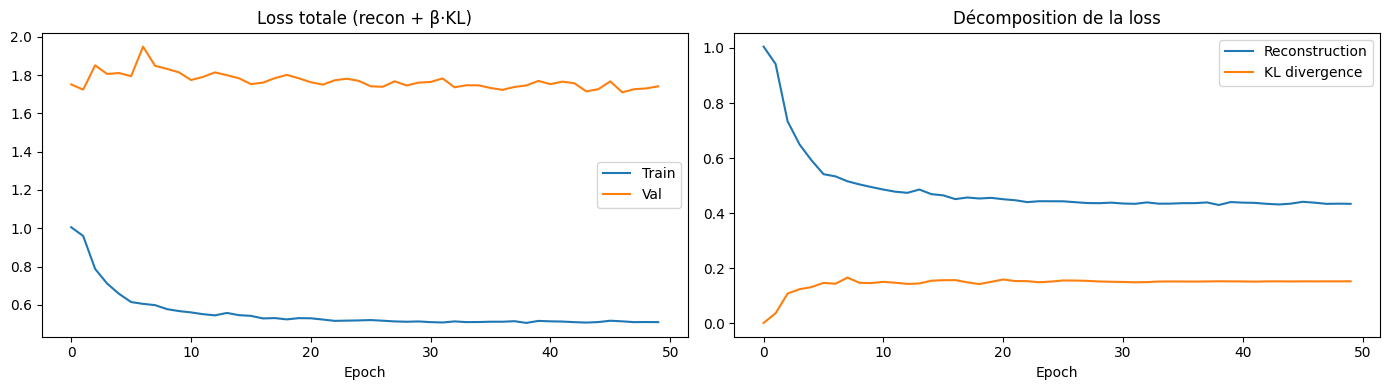

In [ ]:
# ============================================================
# PHASE 2.2 - Entraînement du VAE - FIXED
# ============================================================

import torch.nn.functional as F_torch   # ← même renommage que 2.1
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np

# ── DataLoaders ───────────────────────────────────────────────
train_loader = DataLoader(TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val),   batch_size=BATCH_SIZE, shuffle=False)

# ── Loss VAE ──────────────────────────────────────────────────
def vae_loss(x_recon, x, mu, logvar, kl_weight=KL_WEIGHT):
    recon_loss = F_torch.mse_loss(x_recon, x, reduction='mean')   # ← F_torch
    kl_loss    = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_weight * kl_loss, recon_loss, kl_loss

# ── Optimiseur ────────────────────────────────────────────────
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

# ── Boucle d'entraînement ─────────────────────────────────────
history = {"train_loss": [], "val_loss": [], "recon": [], "kl": []}
best_val_loss = float("inf")

print(f"🚀 Entraînement  —  {EPOCHS} epochs\n")

for epoch in range(1, EPOCHS + 1):

    # -- Train
    model.train()
    train_losses = []
    for (xb,) in train_loader:
        xb = xb.to(device)
        optimizer.zero_grad()
        x_recon, mu, logvar = model(xb)
        loss, rl, kl = vae_loss(x_recon, xb, mu, logvar)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_losses.append((loss.item(), rl.item(), kl.item()))

    t_loss = np.mean([l[0] for l in train_losses])
    t_rl   = np.mean([l[1] for l in train_losses])
    t_kl   = np.mean([l[2] for l in train_losses])

    # -- Validation
    model.eval()
    val_losses = []
    with torch.no_grad():
        for (xb,) in val_loader:
            xb = xb.to(device)
            x_recon, mu, logvar = model(xb)
            loss, _, _ = vae_loss(x_recon, xb, mu, logvar)
            val_losses.append(loss.item())

    v_loss = np.mean(val_losses)
    scheduler.step(v_loss)

    history["train_loss"].append(t_loss)
    history["val_loss"].append(v_loss)
    history["recon"].append(t_rl)
    history["kl"].append(t_kl)

    # -- Sauvegarde meilleur modèle
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), "/content/trading_vae/vae_best.pt")
        tag = " ← best"
    else:
        tag = ""

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{EPOCHS}  |  "
              f"Train {t_loss:.4f}  (recon {t_rl:.4f} | kl {t_kl:.4f})  |  "
              f"Val {v_loss:.4f}{tag}")

print(f"\n✅ Entraînement terminé  —  meilleure val loss : {best_val_loss:.4f}")

# ── Courbes de loss ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"],   label="Val")
axes[0].set_title("Loss totale (recon + β·KL)")
axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history["recon"], label="Reconstruction")
axes[1].plot(history["kl"],    label="KL divergence")
axes[1].set_title("Décomposition de la loss")
axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.savefig("/content/trading_vae/vae_loss.png", dpi=120)
plt.show()

✅ Vecteurs latents  —  Train (826, 32)  |  Val (177, 32)  |  Test (177, 32)
⏳ Calcul t-SNE (peut prendre ~30s)...


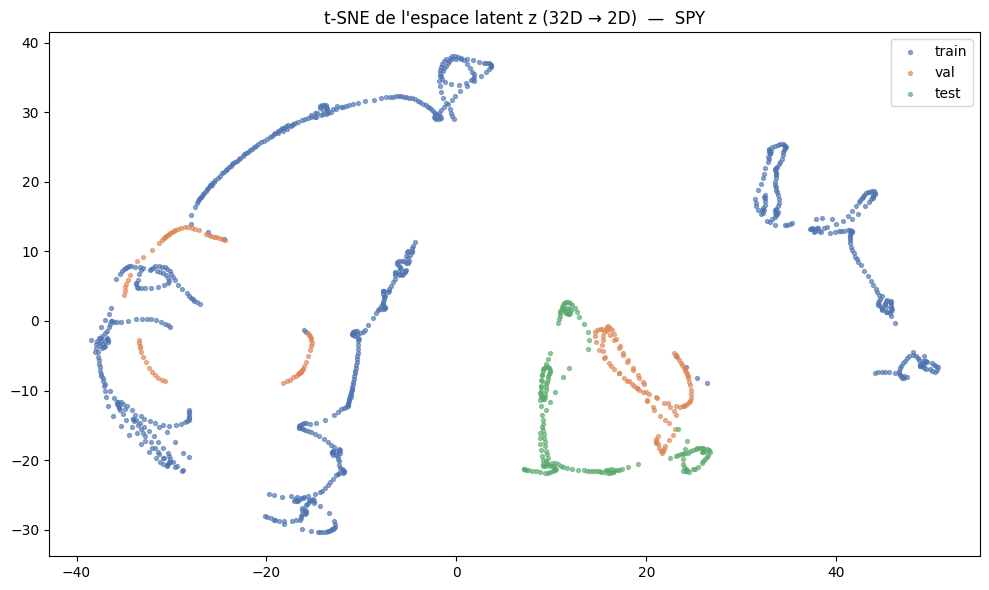

💾 Sauvegardé → /content/trading_vae/phase2_data.pkl
✅ Phase 2 terminée ! Prêt pour la Phase 3 (Gym environment).


In [ ]:
# ============================================================
# PHASE 2.3 - Visualisation espace latent (t-SNE)
# ============================================================

from sklearn.manifold import TSNE

# ── Charger le meilleur modèle ────────────────────────────────
model.load_state_dict(torch.load("/content/trading_vae/vae_best.pt", map_location=device))
model.eval()

# ── Extraire les vecteurs latents z ───────────────────────────
def get_latent(X_tensor):
    loader = DataLoader(TensorDataset(X_tensor), batch_size=256, shuffle=False)
    zs = []
    with torch.no_grad():
        for (xb,) in loader:
            z = model.encode(xb.to(device))
            zs.append(z.cpu().numpy())
    return np.concatenate(zs, axis=0)

Z_train = get_latent(X_train)
Z_val   = get_latent(X_val)
Z_test  = get_latent(X_test)

print(f"✅ Vecteurs latents  —  Train {Z_train.shape}  |  Val {Z_val.shape}  |  Test {Z_test.shape}")

# ── t-SNE sur train ───────────────────────────────────────────
print("⏳ Calcul t-SNE (peut prendre ~30s)...")
Z_all    = np.concatenate([Z_train, Z_val, Z_test], axis=0)
tsne     = TSNE(n_components=2, perplexity=30, random_state=42)
Z_2d     = tsne.fit_transform(Z_all)

labels   = (["train"] * len(Z_train) +
            ["val"]   * len(Z_val)   +
            ["test"]  * len(Z_test))
colors   = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}

plt.figure(figsize=(10, 6))
for split, color in colors.items():
    mask = np.array(labels) == split
    plt.scatter(Z_2d[mask, 0], Z_2d[mask, 1],
                c=color, label=split, s=8, alpha=0.6)
plt.title(f"t-SNE de l'espace latent z ({LATENT_DIM}D → 2D)  —  {TICKER}")
plt.legend(); plt.tight_layout()
plt.savefig("/content/trading_vae/tsne.png", dpi=120)
plt.show()

# ── Sauvegarde Phase 2 ────────────────────────────────────────
with open("/content/trading_vae/phase2_data.pkl", "wb") as f:
    pickle.dump({
        **p1,
        "Z_train"   : Z_train,
        "Z_val"     : Z_val,
        "Z_test"    : Z_test,
        "LATENT_DIM": LATENT_DIM,
    }, f)

print("💾 Sauvegardé → /content/trading_vae/phase2_data.pkl")
print("✅ Phase 2 terminée ! Prêt pour la Phase 3 (Gym environment).")

In [ ]:
# ============================================================
# PHASE 3.1 - Environnement custom OpenAI Gym
# ============================================================

!pip install gymnasium stable-baselines3 -q

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pickle
import torch

# ── Chargement des données Phase 2 ───────────────────────────
with open("/content/trading_vae/phase2_data.pkl", "rb") as f:
    p2 = pickle.load(f)

Z_train     = p2["Z_train"]      # (N_train, 32)
Z_val       = p2["Z_val"]
Z_test      = p2["Z_test"]
df          = p2["df"]
LATENT_DIM  = p2["LATENT_DIM"]
WINDOW      = p2["WINDOW"]
TICKER      = p2["TICKER"]

# Prix de clôture alignés sur les fenêtres
dates_train = p2["dates_train"]
dates_val   = p2["dates_val"]
dates_test  = p2["dates_test"]

close_train = df.loc[dates_train, "close"].values
close_val   = df.loc[dates_val,   "close"].values
close_test  = df.loc[dates_test,  "close"].values

print(f"✅ Données chargées")
print(f"   Z_train : {Z_train.shape}  |  close_train : {close_train.shape}")
print(f"   Z_val   : {Z_val.shape}    |  close_val   : {close_val.shape}")
print(f"   Z_test  : {Z_test.shape}   |  close_test  : {close_test.shape}")

# ============================================================
# ENVIRONNEMENT
# ============================================================
class TradingEnv(gym.Env):
    """
    État   : vecteur latent z du VAE  (LATENT_DIM,)
    Actions: 0 = hold  |  1 = buy  |  2 = sell
    Reward : variation de capital ajustée au risque (Sharpe différentiel)
    """
    metadata = {"render_modes": []}

    def __init__(self, Z, prices, initial_capital=10_000.0,
                 transaction_cost=0.001, slippage=0.0005):
        super().__init__()

        self.Z                = Z.astype(np.float32)
        self.prices           = prices.astype(np.float32)
        self.initial_capital  = initial_capital
        self.transaction_cost = transaction_cost   # 0.1 %
        self.slippage         = slippage           # 0.05 %
        self.n_steps          = len(Z)

        # ── Espaces ──────────────────────────────────────────
        # Action : discret  {0: hold, 1: buy, 2: sell}
        self.action_space = spaces.Discrete(3)

        # Observation : z  +  [position, ratio_capital]
        obs_dim = LATENT_DIM + 2
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(obs_dim,), dtype=np.float32
        )

        # ── Fenêtre pour Sharpe différentiel ─────────────────
        self.returns_window = 20

    # ── Reset ─────────────────────────────────────────────────
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.step_idx      = 0
        self.capital       = self.initial_capital
        self.shares        = 0.0
        self.position      = 0        # 0=flat, 1=long
        self.portfolio_val = self.initial_capital
        self.returns_hist  = []
        self.history       = []

        return self._get_obs(), {}

    # ── Observation ───────────────────────────────────────────
    def _get_obs(self):
        z            = self.Z[self.step_idx]
        position     = np.float32(self.position)
        ratio        = np.float32(self.portfolio_val / self.initial_capital)
        return np.concatenate([z, [position, ratio]])

    # ── Step ──────────────────────────────────────────────────
    def step(self, action):
        price = self.prices[self.step_idx]

        # -- Prix d'exécution avec slippage
        exec_price_buy  = price * (1 + self.slippage)
        exec_price_sell = price * (1 - self.slippage)

        # -- Exécution de l'action
        trade_cost = 0.0

        if action == 1 and self.position == 0:        # BUY
            self.shares   = self.capital / exec_price_buy
            trade_cost    = self.capital * self.transaction_cost
            self.capital  = 0.0
            self.position = 1

        elif action == 2 and self.position == 1:      # SELL
            proceeds      = self.shares * exec_price_sell
            trade_cost    = proceeds * self.transaction_cost
            self.capital  = proceeds - trade_cost
            self.shares   = 0.0
            self.position = 0

        # -- Valeur du portefeuille
        prev_val           = self.portfolio_val
        self.portfolio_val = self.capital + self.shares * price - trade_cost

        # -- Rendement instantané
        ret = (self.portfolio_val - prev_val) / (prev_val + 1e-9)
        self.returns_hist.append(ret)

        # -- Reward : Sharpe différentiel sur fenêtre glissante
        if len(self.returns_hist) >= self.returns_window:
            r_arr  = np.array(self.returns_hist[-self.returns_window:])
            sharpe = r_arr.mean() / (r_arr.std() + 1e-9)
            reward = float(sharpe)
        else:
            reward = float(ret)

        # -- Sauvegarde historique
        self.history.append({
            "step"          : self.step_idx,
            "price"         : price,
            "action"        : action,
            "portfolio_val" : self.portfolio_val,
            "position"      : self.position,
        })

        # -- Avancement
        self.step_idx += 1
        terminated     = self.step_idx >= self.n_steps - 1
        truncated      = False

        return self._get_obs(), reward, terminated, truncated, {}

    # ── Render ────────────────────────────────────────────────
    def render(self):
        h = self.history[-1] if self.history else {}
        print(f"Step {h.get('step',0):4d} | "
              f"Price {h.get('price',0):8.2f} | "
              f"Action {h.get('action',0)} | "
              f"Portfolio {h.get('portfolio_val',0):10.2f}")

print("✅ TradingEnv défini")

✅ Données chargées
   Z_train : (826, 32)  |  close_train : (826,)
   Z_val   : (177, 32)    |  close_val   : (177,)
   Z_test  : (177, 32)   |  close_test  : (177,)
✅ TradingEnv défini


✅ Observation shape : (34,)
   Exemple obs       : [-0.182 -0.34   0.187 -0.073 -0.151] ...
   Action space      : Discrete(3)

📊 Test random policy :
   Capital initial : $10,000.00
   Capital final   : $11,504.57
   Return total    : 15.05%
   Buy & Hold      : 49.71%


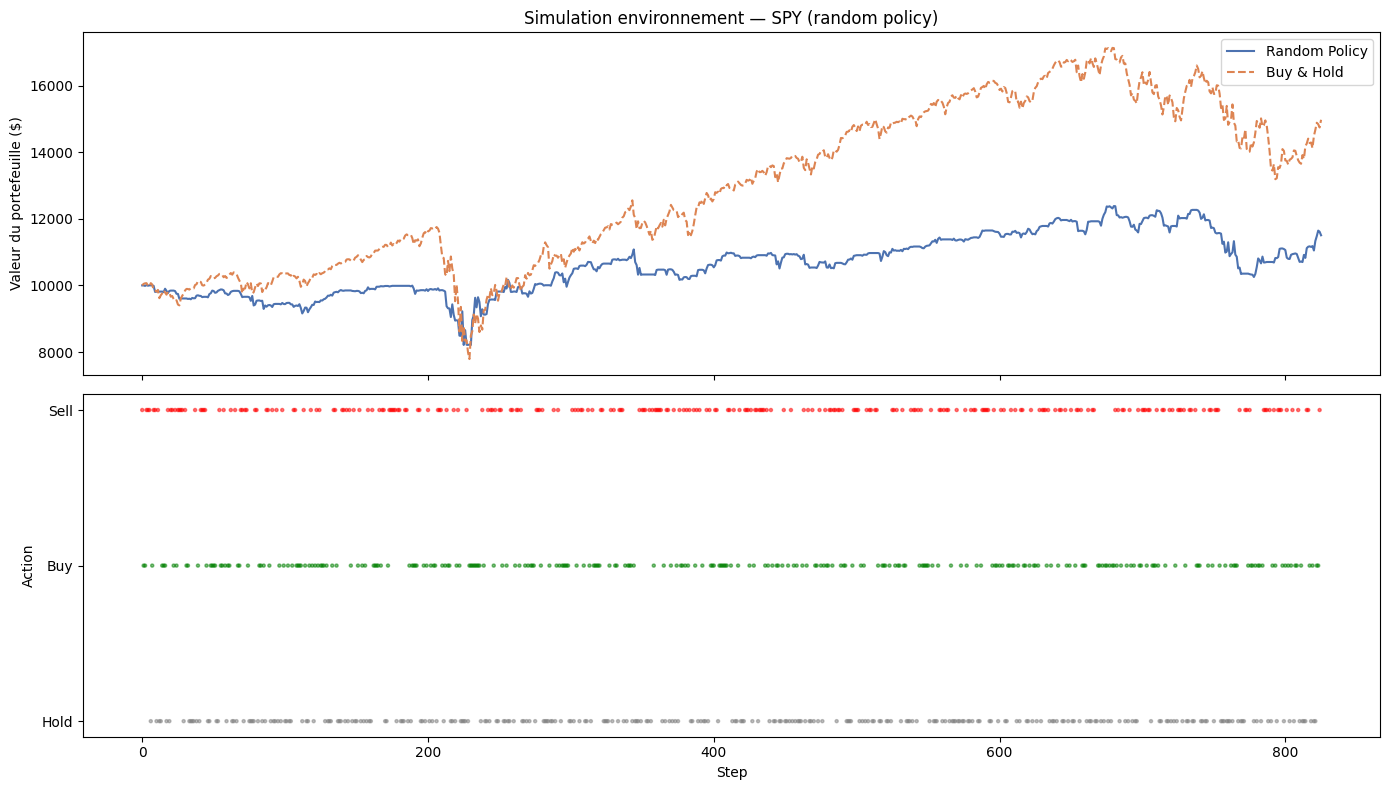


💾 Sauvegardé → /content/trading_vae/phase3_data.pkl
✅ Phase 3 terminée ! Prêt pour la Phase 4 (entraînement DRL).


In [ ]:
# ============================================================
# PHASE 3.2 - Test et validation de l'environnement
# ============================================================

import matplotlib.pyplot as plt

# ── Test rapide avec actions aléatoires ──────────────────────
env = TradingEnv(Z_train, close_train)
obs, _ = env.reset()

print(f"✅ Observation shape : {obs.shape}")
print(f"   Exemple obs       : {obs[:5].round(3)} ...")
print(f"   Action space      : {env.action_space}")

portfolio_vals = [env.initial_capital]
actions_taken  = []

done = False
while not done:
    action = env.action_space.sample()   # action aléatoire
    obs, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated
    portfolio_vals.append(env.portfolio_val)
    actions_taken.append(action)

final_val   = env.portfolio_val
total_return = (final_val - env.initial_capital) / env.initial_capital * 100
print(f"\n📊 Test random policy :")
print(f"   Capital initial : ${env.initial_capital:,.2f}")
print(f"   Capital final   : ${final_val:,.2f}")
print(f"   Return total    : {total_return:.2f}%")

# ── Buy & Hold baseline ───────────────────────────────────────
bh_return = (close_train[-1] - close_train[0]) / close_train[0] * 100
print(f"   Buy & Hold      : {bh_return:.2f}%")

# ── Visualisation ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Portfolio value
axes[0].plot(portfolio_vals, label="Random Policy", color="#4C72B0")
bh_vals = env.initial_capital * (close_train / close_train[0])
axes[0].plot(bh_vals, label="Buy & Hold", color="#DD8452", linestyle="--")
axes[0].set_ylabel("Valeur du portefeuille ($)")
axes[0].set_title(f"Simulation environnement — {TICKER} (random policy)")
axes[0].legend()

# Actions
colors_act = {0: "gray", 1: "green", 2: "red"}
action_colors = [colors_act[a] for a in actions_taken]
axes[1].scatter(range(len(actions_taken)), actions_taken,
                c=action_colors, s=5, alpha=0.5)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(["Hold", "Buy", "Sell"])
axes[1].set_ylabel("Action")
axes[1].set_xlabel("Step")

plt.tight_layout()
plt.savefig("/content/trading_vae/env_test.png", dpi=120)
plt.show()

# ── Sauvegarde Phase 3 ────────────────────────────────────────
import pickle

with open("/content/trading_vae/phase3_data.pkl", "wb") as f:
    pickle.dump({
        **p2,
        "close_train" : close_train,
        "close_val"   : close_val,
        "close_test"  : close_test,
    }, f)

print("\n💾 Sauvegardé → /content/trading_vae/phase3_data.pkl")
print("✅ Phase 3 terminée ! Prêt pour la Phase 4 (entraînement DRL).")

 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 99,998/100,000  [ 0:35:50 < 0:00:01 , 43 it/s ]

✅ TD3 — meilleur return val : +5.82%


  Algo       Best Val Return
  PPO                +1.84%
  SAC                +8.76%
  TD3                +5.82%


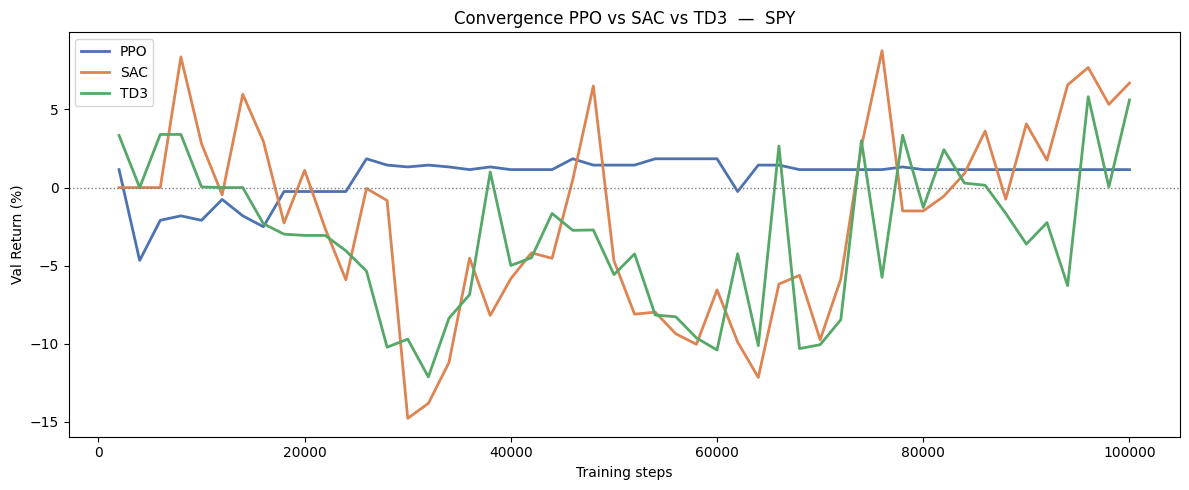


💾 Sauvegardé → /content/trading_vae/phase4_data.pkl
🏆 Meilleur algo : SAC  (+8.76%)
✅ Phase 4 terminée ! Prêt pour la Phase 4.2 (ablation study).


In [ ]:
# ============================================================
# PHASE 4.1 - Comparaison PPO vs SAC vs TD3
# ============================================================

from stable_baselines3 import PPO, SAC, TD3
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise
import numpy as np, os, pickle

# ── Chargement Phase 3 ───────────────────────────────────────
with open("/content/trading_vae/phase3_data.pkl", "rb") as f:
    p3 = pickle.load(f)

Z_train     = p3["Z_train"]
Z_val       = p3["Z_val"]
close_train = p3["close_train"]
close_val   = p3["close_val"]
LATENT_DIM  = p3["LATENT_DIM"]
TICKER      = p3["TICKER"]

os.makedirs("/content/trading_vae/models", exist_ok=True)
os.makedirs("/content/trading_vae/logs",   exist_ok=True)

TIMESTEPS = 100_000

# ── Callback ─────────────────────────────────────────────────
class TradingCallback(BaseCallback):
    def __init__(self, eval_env, algo_name, eval_freq=2000, verbose=1):
        super().__init__(verbose)
        self.eval_env    = eval_env
        self.algo_name   = algo_name
        self.eval_freq   = eval_freq
        self.best_return = -np.inf
        self.returns_log = []

    def _on_step(self):
        if self.n_calls % self.eval_freq == 0:
            obs, _ = self.eval_env.reset()
            done   = False
            init_cap = self.eval_env.unwrapped.initial_capital
            while not done:
                action, _ = self.model.predict(obs, deterministic=True)
                obs, _, terminated, truncated, _ = self.eval_env.step(action)
                done = terminated or truncated
            final_val = self.eval_env.unwrapped.portfolio_val
            total_ret = (final_val - init_cap) / init_cap * 100
            self.returns_log.append((self.n_calls, total_ret))
            if total_ret > self.best_return:
                self.best_return = total_ret
                self.model.save(f"/content/trading_vae/models/best_{self.algo_name}")
                tag = " ← best"
            else:
                tag = ""
            if self.verbose:
                print(f"  [{self.algo_name}] Step {self.n_calls:6d}  |  "
                      f"Val return : {total_ret:+.2f}%{tag}")
        return True

# ============================================================
# ENTRAÎNEMENT DES 3 ALGOS
# ============================================================
results = {}

# ── 1. PPO ───────────────────────────────────────────────────
print("\n" + "="*55)
print("🚀  PPO — Proximal Policy Optimization")
print("="*55)

train_env_ppo = Monitor(TradingEnv(Z_train, close_train))
val_env_ppo   = Monitor(TradingEnv(Z_val,   close_val))
cb_ppo        = TradingCallback(val_env_ppo, "PPO", eval_freq=2000)

model_ppo = PPO(
    "MlpPolicy", train_env_ppo,
    learning_rate  = 3e-4,
    n_steps        = 512,
    batch_size     = 64,
    n_epochs       = 10,
    gamma          = 0.99,
    gae_lambda     = 0.95,
    clip_range     = 0.2,
    ent_coef       = 0.01,
    verbose        = 0,
    device         = "cpu"
)
model_ppo.learn(TIMESTEPS, callback=cb_ppo, progress_bar=True)
model_ppo.save("/content/trading_vae/models/ppo_final")
results["PPO"] = {"model": model_ppo, "best_return": cb_ppo.best_return,
                  "returns_log": cb_ppo.returns_log}
print(f"✅ PPO — meilleur return val : {cb_ppo.best_return:+.2f}%")

# ── 2. SAC ───────────────────────────────────────────────────
# SAC nécessite un action space continu → on wrap l'env
from gymnasium import spaces as gym_spaces

class ContinuousTradingEnv(TradingEnv):
    """
    Wrapper continu pour SAC/TD3 :
    action ∈ [-1, 1]
      < -0.33 → sell
      > +0.33 → buy
      sinon   → hold
    """
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.action_space = gym_spaces.Box(
            low=-1.0, high=1.0, shape=(1,), dtype=np.float32)

    def step(self, action):
        a = float(action[0])
        if   a >  0.33: discrete = 1   # buy
        elif a < -0.33: discrete = 2   # sell
        else:           discrete = 0   # hold
        return super().step(discrete)

print("\n" + "="*55)
print("🚀  SAC — Soft Actor-Critic")
print("="*55)

train_env_sac = Monitor(ContinuousTradingEnv(Z_train, close_train))
val_env_sac   = Monitor(ContinuousTradingEnv(Z_val,   close_val))
cb_sac        = TradingCallback(val_env_sac, "SAC", eval_freq=2000)

model_sac = SAC(
    "MlpPolicy", train_env_sac,
    learning_rate  = 3e-4,
    buffer_size    = 50_000,
    batch_size     = 256,
    gamma          = 0.99,
    tau            = 0.005,
    ent_coef       = "auto",
    verbose        = 0,
    device         = "cpu"
)
model_sac.learn(TIMESTEPS, callback=cb_sac, progress_bar=True)
model_sac.save("/content/trading_vae/models/sac_final")
results["SAC"] = {"model": model_sac, "best_return": cb_sac.best_return,
                  "returns_log": cb_sac.returns_log}
print(f"✅ SAC — meilleur return val : {cb_sac.best_return:+.2f}%")

# ── 3. TD3 ───────────────────────────────────────────────────
print("\n" + "="*55)
print("🚀  TD3 — Twin Delayed DDPG")
print("="*55)

train_env_td3 = Monitor(ContinuousTradingEnv(Z_train, close_train))
val_env_td3   = Monitor(ContinuousTradingEnv(Z_val,   close_val))
cb_td3        = TradingCallback(val_env_td3, "TD3", eval_freq=2000)

n_actions    = train_env_td3.action_space.shape[-1]
action_noise = NormalActionNoise(
    mean  = np.zeros(n_actions),
    sigma = 0.1 * np.ones(n_actions)
)

model_td3 = TD3(
    "MlpPolicy", train_env_td3,
    learning_rate  = 3e-4,
    buffer_size    = 50_000,
    batch_size     = 256,
    gamma          = 0.99,
    tau            = 0.005,
    action_noise   = action_noise,
    policy_delay   = 2,
    verbose        = 0,
    device         = "cpu"
)
model_td3.learn(TIMESTEPS, callback=cb_td3, progress_bar=True)
model_td3.save("/content/trading_vae/models/td3_final")
results["TD3"] = {"model": model_td3, "best_return": cb_td3.best_return,
                  "returns_log": cb_td3.returns_log}
print(f"✅ TD3 — meilleur return val : {cb_td3.best_return:+.2f}%")

# ── Tableau récapitulatif ─────────────────────────────────────
print(f"\n\n{'='*40}")
print(f"  {'Algo':<8}  {'Best Val Return':>16}")
print(f"{'='*40}")
for algo, res in results.items():
    print(f"  {algo:<8}  {res['best_return']:>+14.2f}%")
print(f"{'='*40}")

# ── Courbe de convergence des 3 algos ────────────────────────
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
colors = {"PPO": "#4C72B0", "SAC": "#DD8452", "TD3": "#55A868"}
for algo, res in results.items():
    steps   = [r[0] for r in res["returns_log"]]
    returns = [r[1] for r in res["returns_log"]]
    plt.plot(steps, returns, label=algo, color=colors[algo], linewidth=2)

plt.axhline(0, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Training steps")
plt.ylabel("Val Return (%)")
plt.title(f"Convergence PPO vs SAC vs TD3  —  {TICKER}")
plt.legend()
plt.tight_layout()
plt.savefig("/content/trading_vae/algo_comparison.png", dpi=120)
plt.show()

# ── Sauvegarde ───────────────────────────────────────────────
with open("/content/trading_vae/phase4_data.pkl", "wb") as f:
    pickle.dump({
        **p3,
        "results"  : {k: {"best_return": v["best_return"],
                          "returns_log": v["returns_log"]}
                      for k, v in results.items()},
        "best_algo": max(results, key=lambda k: results[k]["best_return"])
    }, f)

best_algo = max(results, key=lambda k: results[k]["best_return"])
print(f"\n💾 Sauvegardé → /content/trading_vae/phase4_data.pkl")
print(f"🏆 Meilleur algo : {best_algo}  ({results[best_algo]['best_return']:+.2f}%)")
print("✅ Phase 4 terminée ! Prêt pour la Phase 4.2 (ablation study).")

In [ ]:
# ── Installation ─────────────────────────────────────────────
!pip install stable-baselines3[extra] gymnasium -q

print("✅ stable-baselines3 installé")

✅ stable-baselines3 installé


 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 99,994/100,000  [ 0:35:02 < 0:00:01 , 46 it/s ]

[SAC_raw] Step 100000  |  Val return : +1.43%

✅ SAC sans VAE — meilleur return val : +13.27%

  Stratégie                Return   Sharpe    MaxDD   WinRate  Trades
  DRL + VAE (SAC)          +6.58%    1.495    -5.88%      10.9%     172
  DRL sans VAE             +0.00%    0.000     0.00%       0.0%     176
  Buy & Hold              +16.35%    1.922    -9.97%      56.6%       1


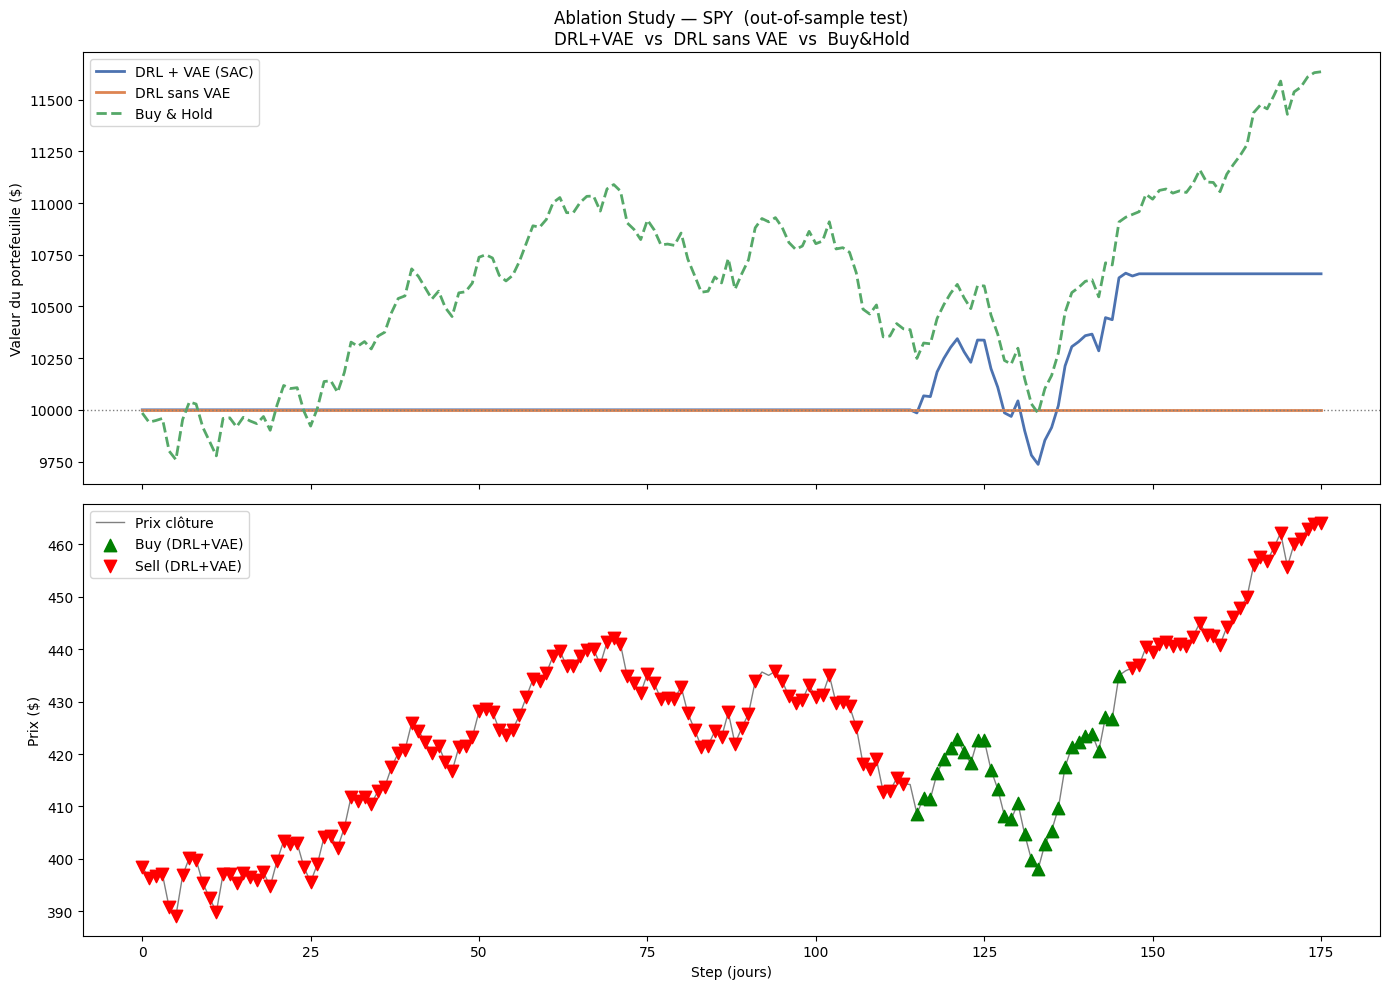


💾 Sauvegardé → /content/trading_vae/phase4_data.pkl
✅ Phase 4.2 terminée ! Prêt pour la Phase 5 (backtesting complet).


In [ ]:
# ============================================================
# PHASE 4.2 - Ablation Study
# DRL+VAE  vs  DRL sans VAE  vs  Buy&Hold
# ============================================================

from stable_baselines3 import SAC, PPO
from stable_baselines3.common.monitor import Monitor
from gymnasium import spaces as gym_spaces
import numpy as np, pickle, matplotlib.pyplot as plt

# ── Chargement ────────────────────────────────────────────────
with open("/content/trading_vae/phase4_data.pkl", "rb") as f:
    p4 = pickle.load(f)

with open("/content/trading_vae/phase1_data.pkl", "rb") as f:
    p1 = pickle.load(f)

Z_train     = p4["Z_train"]
Z_val       = p4["Z_val"]
Z_test      = p4["Z_test"]
close_train = p4["close_train"]
close_val   = p4["close_val"]
close_test  = p4["close_test"]
LATENT_DIM  = p4["LATENT_DIM"]
TICKER      = p4["TICKER"]

# ── Données brutes (sans VAE) ─────────────────────────────────
# On utilise les features normalisées aplaties sur le dernier timestep
X_train_raw = p1["X_train"][:, -1, :]   # (N, n_features) dernier pas de temps
X_val_raw   = p1["X_val"][:,   -1, :]
X_test_raw  = p1["X_test"][:,  -1, :]

RAW_DIM = X_train_raw.shape[1]
print(f"✅ Données chargées")
print(f"   Avec VAE    : state dim = {LATENT_DIM + 2}")
print(f"   Sans VAE    : state dim = {RAW_DIM + 2}")

# ============================================================
# ENV SANS VAE  (utilise les features brutes au lieu de z)
# ============================================================
class TradingEnvRaw(TradingEnv):
    """
    Identique à TradingEnv mais l'état = features brutes
    au lieu du vecteur latent z du VAE.
    """
    def __init__(self, X_raw, prices, **kwargs):
        # on passe X_raw comme Z pour réutiliser la logique
        super().__init__(X_raw, prices, **kwargs)
        obs_dim = X_raw.shape[1] + 2
        self.observation_space = gym_spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(obs_dim,), dtype=np.float32
        )

# ── Env continu pour SAC sans VAE ────────────────────────────
class ContinuousTradingEnvRaw(TradingEnvRaw):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.action_space = gym_spaces.Box(
            low=-1.0, high=1.0, shape=(1,), dtype=np.float32)

    def step(self, action):
        a = float(action[0])
        if   a >  0.33: discrete = 1
        elif a < -0.33: discrete = 2
        else:           discrete = 0
        return TradingEnvRaw.step(self, discrete)

# ============================================================
# ENTRAÎNEMENT DRL SANS VAE  (SAC sur features brutes)
# ============================================================
print("\n🚀 Entraînement SAC sans VAE (features brutes)...")

train_env_raw = Monitor(ContinuousTradingEnvRaw(X_train_raw, close_train))
val_env_raw   = Monitor(ContinuousTradingEnvRaw(X_val_raw,   close_val))
cb_raw        = TradingCallback(val_env_raw, "SAC_raw", eval_freq=2000)

model_raw = SAC(
    "MlpPolicy", train_env_raw,
    learning_rate = 3e-4,
    buffer_size   = 50_000,
    batch_size    = 256,
    gamma         = 0.99,
    tau           = 0.005,
    ent_coef      = "auto",
    verbose       = 0,
    device        = "cpu"
)
model_raw.learn(100_000, callback=cb_raw, progress_bar=True)
model_raw.save("/content/trading_vae/models/sac_raw_final")
print(f"✅ SAC sans VAE — meilleur return val : {cb_raw.best_return:+.2f}%")

# ============================================================
# ÉVALUATION SUR TEST (out-of-sample)
# ============================================================
def _max_drawdown(portfolio):
    p    = np.array(portfolio)
    peak = np.maximum.accumulate(p)
    dd   = (p - peak) / (peak + 1e-9) * 100
    return float(dd.min())

def full_eval(model, env, label, is_continuous=False):
    obs, _ = env.reset()
    done   = False
    init_cap = env.unwrapped.initial_capital

    while not done:
        if model is not None:
            action, _ = model.predict(obs, deterministic=True)
        else:
            action = np.array([0.0]) if is_continuous else 0
        obs, _, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

    history   = env.unwrapped.history
    portfolio = [h["portfolio_val"] for h in history]
    actions   = [h["action"]        for h in history]
    prices    = env.unwrapped.prices[:len(portfolio)]

    returns    = np.diff(portfolio) / (np.array(portfolio[:-1]) + 1e-9)
    total_ret  = (portfolio[-1] - init_cap) / init_cap * 100
    sharpe     = returns.mean() / (returns.std() + 1e-9) * np.sqrt(252)
    max_dd     = _max_drawdown(portfolio)
    n_trades   = sum(1 for a in actions if a != 0)
    win_rate   = sum(1 for r in returns if r > 0) / (len(returns) + 1e-9) * 100

    return {
        "label"    : label,
        "portfolio": portfolio,
        "actions"  : actions,
        "prices"   : prices,
        "return"   : total_ret,
        "sharpe"   : sharpe,
        "max_dd"   : max_dd,
        "n_trades" : n_trades,
        "win_rate" : win_rate,
    }

# ── 1. DRL + VAE (SAC) ───────────────────────────────────────
best_sac = SAC.load("/content/trading_vae/models/best_SAC")
test_env_vae = Monitor(ContinuousTradingEnv(Z_test, close_test))
res_vae = full_eval(best_sac, test_env_vae, "DRL + VAE (SAC)", is_continuous=True)

# ── 2. DRL sans VAE (SAC raw) ────────────────────────────────
best_raw = SAC.load("/content/trading_vae/models/sac_raw_final")
test_env_raw = Monitor(ContinuousTradingEnvRaw(X_test_raw, close_test))
res_raw = full_eval(best_raw, test_env_raw, "DRL sans VAE", is_continuous=True)

# ── 3. Buy & Hold ────────────────────────────────────────────
test_env_bh = Monitor(TradingEnv(Z_test, close_test))
obs, _ = test_env_bh.reset()
test_env_bh.step(1)   # achète au début
done = False
while not done:
    obs, _, terminated, truncated, _ = test_env_bh.step(0)
    done = terminated or truncated
port_bh   = [h["portfolio_val"] for h in test_env_bh.unwrapped.history]
ret_bh    = (port_bh[-1] - 10_000) / 10_000 * 100
r_bh      = np.diff(port_bh) / (np.array(port_bh[:-1]) + 1e-9)
res_bh = {
    "label"    : "Buy & Hold",
    "portfolio": port_bh,
    "return"   : ret_bh,
    "sharpe"   : r_bh.mean() / (r_bh.std() + 1e-9) * np.sqrt(252),
    "max_dd"   : _max_drawdown(port_bh),
    "n_trades" : 1,
    "win_rate" : sum(1 for r in r_bh if r > 0) / len(r_bh) * 100,
}

# ── Tableau comparatif ────────────────────────────────────────
all_res = [res_vae, res_raw, res_bh]

print(f"\n{'='*70}")
print(f"  {'Stratégie':<22} {'Return':>8} {'Sharpe':>8} {'MaxDD':>8} "
      f"{'WinRate':>9} {'Trades':>7}")
print(f"{'='*70}")
for r in all_res:
    print(f"  {r['label']:<22} "
          f"{r['return']:>+7.2f}%  "
          f"{r['sharpe']:>7.3f}  "
          f"{r['max_dd']:>7.2f}%  "
          f"{r['win_rate']:>8.1f}%  "
          f"{r['n_trades']:>6}")
print(f"{'='*70}")

# ── Visualisation ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
colors = {
    "DRL + VAE (SAC)": "#4C72B0",
    "DRL sans VAE"   : "#DD8452",
    "Buy & Hold"     : "#55A868",
}

# -- Courbe portfolio
for r in all_res:
    ls = "--" if r["label"] == "Buy & Hold" else "-"
    axes[0].plot(r["portfolio"], label=r["label"],
                 color=colors[r["label"]], linewidth=2, linestyle=ls)
axes[0].axhline(10_000, color="gray", linestyle=":", linewidth=1)
axes[0].set_ylabel("Valeur du portefeuille ($)")
axes[0].set_title(f"Ablation Study — {TICKER}  (out-of-sample test)\n"
                  f"DRL+VAE  vs  DRL sans VAE  vs  Buy&Hold")
axes[0].legend()

# -- Actions DRL+VAE sur le prix
buy_steps  = [i for i, a in enumerate(res_vae["actions"]) if a == 1]
sell_steps = [i for i, a in enumerate(res_vae["actions"]) if a == 2]
axes[1].plot(close_test[:len(res_vae["actions"])],
             color="gray", linewidth=1, label="Prix clôture")
axes[1].scatter(buy_steps,  close_test[buy_steps],
                marker="^", color="green", s=80, label="Buy (DRL+VAE)",  zorder=5)
axes[1].scatter(sell_steps, close_test[sell_steps],
                marker="v", color="red",   s=80, label="Sell (DRL+VAE)", zorder=5)
axes[1].set_ylabel("Prix ($)")
axes[1].set_xlabel("Step (jours)")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/trading_vae/ablation_study.png", dpi=120)
plt.show()

# ── Sauvegarde ────────────────────────────────────────────────
with open("/content/trading_vae/phase4_data.pkl", "wb") as f:
    pickle.dump({
        **p4,
        "res_vae" : {k: v for k, v in res_vae.items() if k != "actions"},
        "res_raw" : {k: v for k, v in res_raw.items() if k != "actions"},
        "res_bh"  : res_bh,
    }, f)

print("\n💾 Sauvegardé → /content/trading_vae/phase4_data.pkl")
print("✅ Phase 4.2 terminée ! Prêt pour la Phase 5 (backtesting complet).")

In [ ]:
# ============================================================
# PHASE 5.1 - Backtesting complet & métriques
# ============================================================

!pip install quantstats pyfolio-reloaded -q

import quantstats as qs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle, warnings
warnings.filterwarnings('ignore')

# ── Chargement Phase 4 ───────────────────────────────────────
with open("/content/trading_vae/phase4_data.pkl", "rb") as f:
    p4 = pickle.load(f)

res_vae = p4["res_vae"]
res_raw = p4["res_raw"]
res_bh  = p4["res_bh"]

close_test  = p4["close_test"]
dates_test  = p4["dates_test"]
TICKER      = p4["TICKER"]

# ── Reconstruction des séries temporelles ────────────────────
def portfolio_to_returns(portfolio, dates):
    port = pd.Series(portfolio, index=dates[:len(portfolio)])
    returns = port.pct_change().dropna()
    return returns

n = min(len(res_vae["portfolio"]), len(res_raw["portfolio"]),
        len(res_bh["portfolio"]),  len(dates_test))

dates_idx = pd.to_datetime(dates_test[:n])

ret_vae = portfolio_to_returns(res_vae["portfolio"][:n], dates_idx)
ret_raw = portfolio_to_returns(res_raw["portfolio"][:n], dates_idx)
ret_bh  = portfolio_to_returns(res_bh["portfolio"][:n],  dates_idx)

# Buy&Hold benchmark (prix SPY)
spy_ret = pd.Series(
    np.diff(close_test[:n]) / close_test[:n-1],
    index=dates_idx[1:]
)

print("✅ Séries de rendements construites")
print(f"   Période : {dates_idx[0].date()} → {dates_idx[-1].date()}")
print(f"   Nb jours : {len(ret_vae)}")

# ============================================================
# MÉTRIQUES COMPLÈTES
# ============================================================
def compute_metrics(returns, label, initial_capital=10_000):
    r = returns.dropna()
    portfolio = initial_capital * (1 + r).cumprod()

    # -- Rendements
    total_ret    = (portfolio.iloc[-1] / initial_capital - 1) * 100
    annual_ret   = ((1 + total_ret/100) ** (252/len(r)) - 1) * 100

    # -- Risque
    annual_vol   = r.std() * np.sqrt(252) * 100
    sharpe       = (r.mean() / (r.std() + 1e-9)) * np.sqrt(252)
    sortino_r    = r[r < 0].std() + 1e-9
    sortino      = (r.mean() / sortino_r) * np.sqrt(252)

    # -- Drawdown
    peak         = portfolio.cummax()
    dd           = (portfolio - peak) / (peak + 1e-9) * 100
    max_dd       = dd.min()
    avg_dd       = dd[dd < 0].mean()

    # -- Win rate & profit factor
    wins         = r[r > 0]
    losses       = r[r < 0]
    win_rate     = len(wins) / (len(wins) + len(losses) + 1e-9) * 100
    profit_factor= wins.sum() / (abs(losses.sum()) + 1e-9)

    # -- Calmar ratio
    calmar       = annual_ret / (abs(max_dd) + 1e-9)

    metrics = {
        "label"         : label,
        "Total Return"  : f"{total_ret:+.2f}%",
        "Annual Return" : f"{annual_ret:+.2f}%",
        "Annual Vol"    : f"{annual_vol:.2f}%",
        "Sharpe"        : f"{sharpe:.3f}",
        "Sortino"       : f"{sortino:.3f}",
        "Max Drawdown"  : f"{max_dd:.2f}%",
        "Avg Drawdown"  : f"{avg_dd:.2f}%",
        "Win Rate"      : f"{win_rate:.1f}%",
        "Profit Factor" : f"{profit_factor:.3f}",
        "Calmar Ratio"  : f"{calmar:.3f}",
    }
    return metrics, portfolio, dd

metrics_vae, port_vae, dd_vae = compute_metrics(ret_vae, "DRL + VAE (SAC)")
metrics_raw, port_raw, dd_raw = compute_metrics(ret_raw, "DRL sans VAE")
metrics_bh,  port_bh,  dd_bh  = compute_metrics(ret_bh,  "Buy & Hold")

# ── Tableau final ─────────────────────────────────────────────
all_metrics = [metrics_vae, metrics_raw, metrics_bh]
keys        = [k for k in metrics_vae.keys() if k != "label"]

print(f"\n{'='*65}")
print(f"  {'Métrique':<18} {'DRL+VAE':>14} {'DRL sans VAE':>14} {'Buy&Hold':>12}")
print(f"{'='*65}")
for k in keys:
    print(f"  {k:<18} {metrics_vae[k]:>14} {metrics_raw[k]:>14} {metrics_bh[k]:>12}")
print(f"{'='*65}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 53.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.6 MB/s eta 0:00:00
✅ Séries de rendements construites
   Période : 2023-04-19 → 2023-12-28
   Nb jours : 175

  Métrique                  DRL+VAE   DRL sans VAE     Buy&Hold
  Total Return               +6.58%         +0.00%      +16.53%
  Annual Return              +9.61%         +0.00%      +24.64%
  Annual Vol                  6.29%          0.00%       11.86%
  Sharpe                      1.491          0.000        1.916
  Sortino                     1.155            nan        3.209
  Max Drawdown               -5.88%          0.00%       -9.97%
  Avg Drawdown 

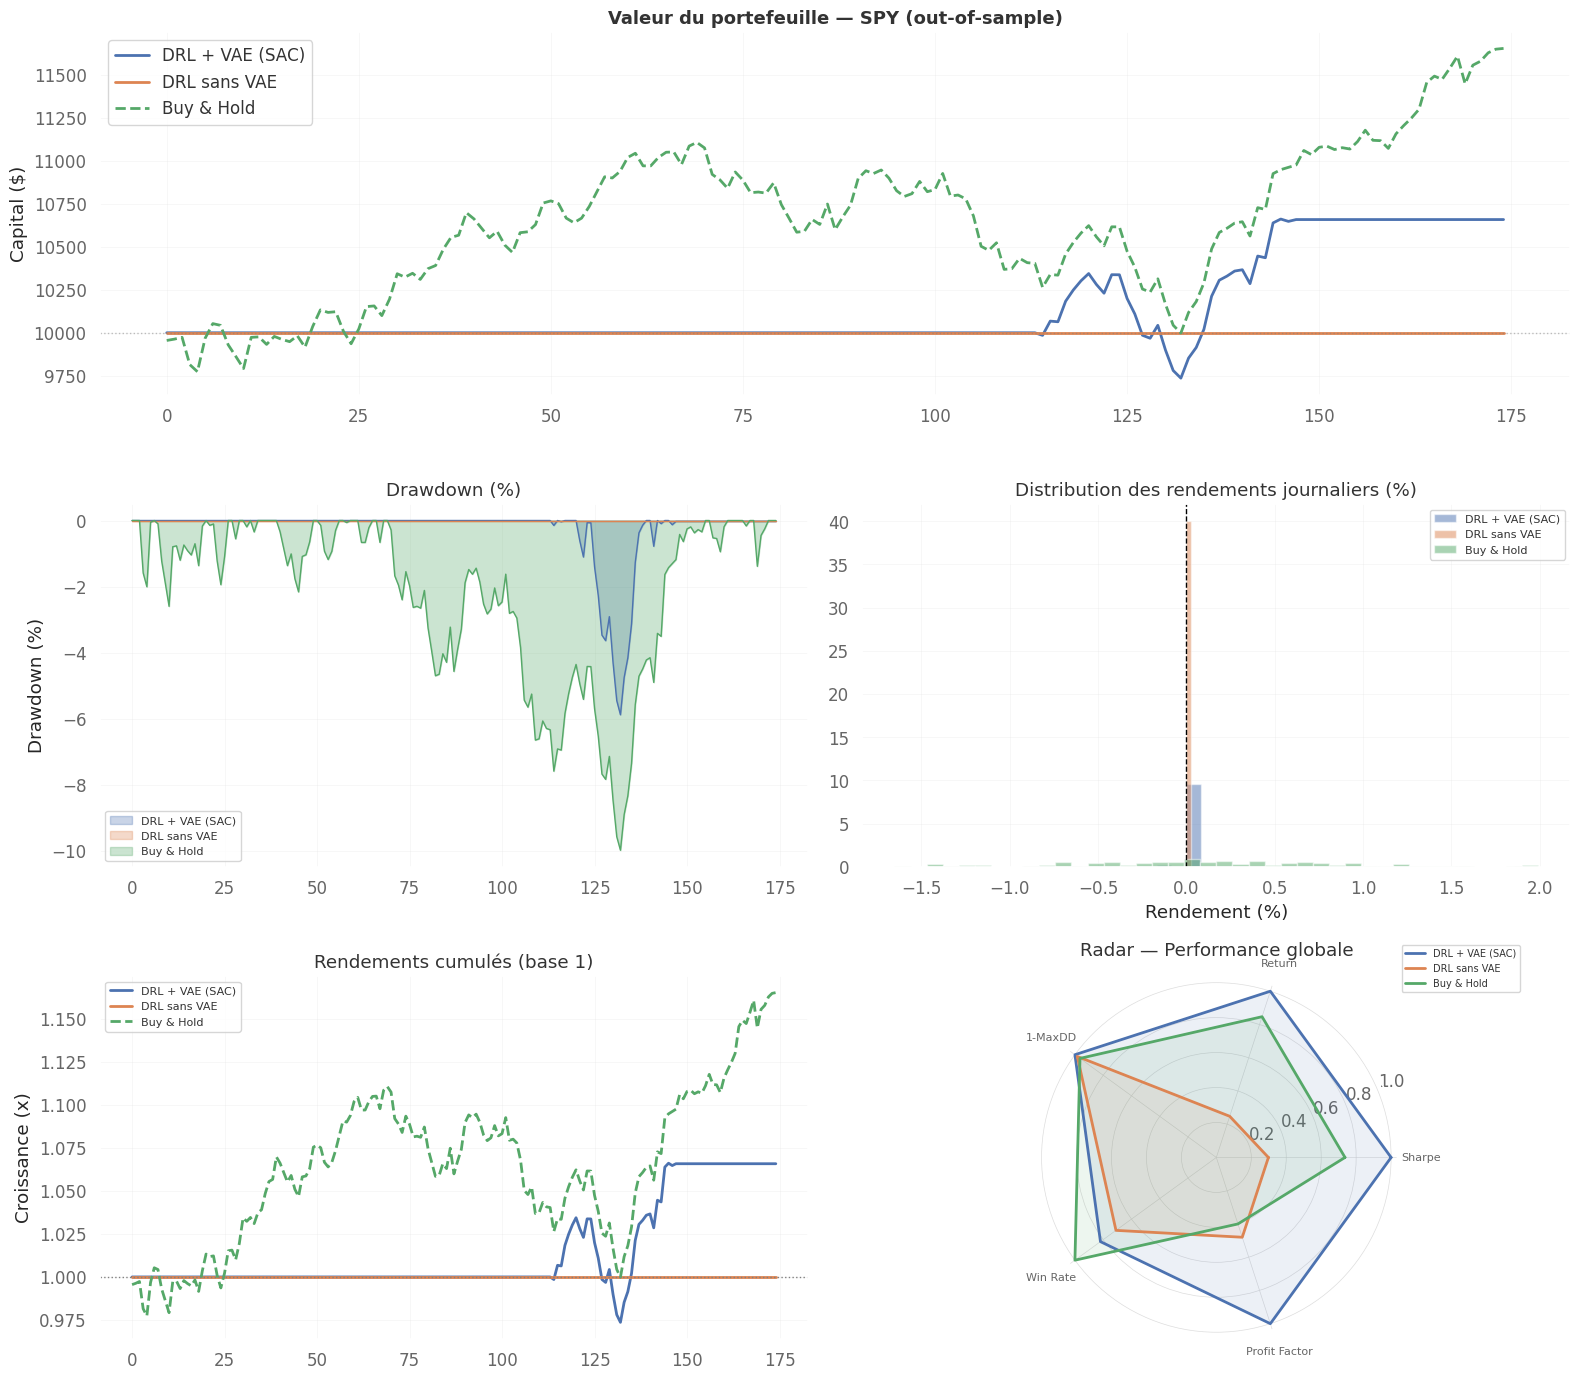


📊 Rapport QuantStats — DRL + VAE (SAC):
                 Parameters
----------------------------------------
Benchmark                      BENCHMARK
Periods/Year                         252
Risk-Free Rate                     0.0%
Compounded                           Yes
Match Dates                          Yes

[Performance Metrics]


Parameter       Value
--------------  ---------
Benchmark       Benchmark
Risk-Free Rate  0.0%
Periods/Year    252
Compounded      Yes
Match Dates     Yes


                     Benchmark    Strategy
-------------------  -----------  ----------
Start Period         2023-10-03   2023-10-03
End Period           2023-12-28   2023-12-28
Risk-Free Rate       0.0%         0.0%
Time in Market       100.0%       56.0%

Cumulative Return    12.01%       6.58%
CAGR﹪               59.76%       30.12%

Sharpe               3.89         2.53
Prob. Sharpe Ratio   96.93%       89.92%
Sortino              6.43         4.39
Sortino/√2           4.55         3.11
Omega  

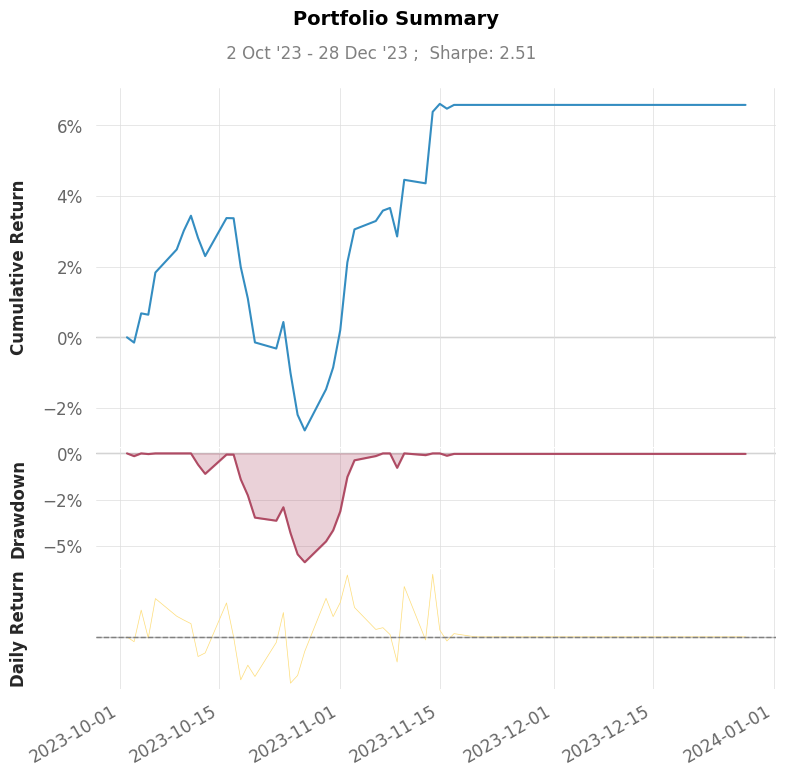

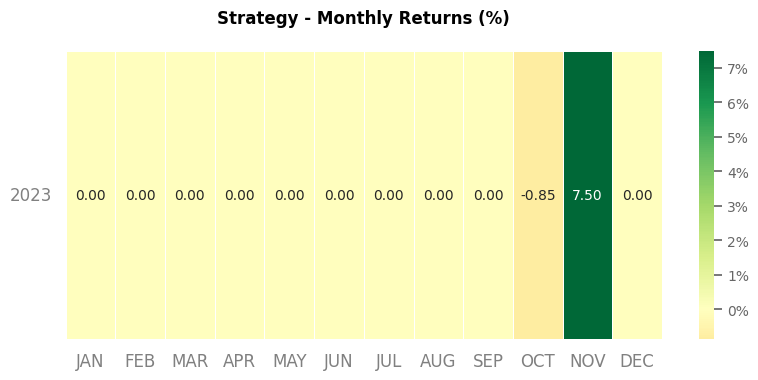


💾 Sauvegardé → /content/trading_vae/phase5_data.pkl
✅ Phase 5 terminée ! Prêt pour la Phase 6 (Dashboard).


In [ ]:
# ============================================================
# PHASE 5.2 - Visualisations backtesting
# ============================================================

fig = plt.figure(figsize=(16, 14))
colors = {
    "DRL + VAE (SAC)": "#4C72B0",
    "DRL sans VAE"   : "#DD8452",
    "Buy & Hold"     : "#55A868",
}

# ── 1. Courbe de capital cumulé ───────────────────────────────
ax1 = fig.add_subplot(3, 2, (1, 2))
for port, label in [(port_vae, "DRL + VAE (SAC)"),
                    (port_raw, "DRL sans VAE"),
                    (port_bh,  "Buy & Hold")]:
    ls = "--" if label == "Buy & Hold" else "-"
    ax1.plot(port.values, label=label,
             color=colors[label], linewidth=2, linestyle=ls)
ax1.axhline(10_000, color="gray", linestyle=":", linewidth=1, alpha=0.5)
ax1.set_title(f"Valeur du portefeuille — {TICKER} (out-of-sample)",
              fontsize=13, fontweight="bold")
ax1.set_ylabel("Capital ($)")
ax1.legend()
ax1.grid(alpha=0.3)

# ── 2. Drawdown ───────────────────────────────────────────────
ax2 = fig.add_subplot(3, 2, 3)
for dd, label in [(dd_vae, "DRL + VAE (SAC)"),
                  (dd_raw, "DRL sans VAE"),
                  (dd_bh,  "Buy & Hold")]:
    ax2.fill_between(range(len(dd)), dd.values, 0,
                     alpha=0.3, color=colors[label], label=label)
    ax2.plot(dd.values, color=colors[label], linewidth=1)
ax2.set_title("Drawdown (%)")
ax2.set_ylabel("Drawdown (%)")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# ── 3. Distribution des rendements ───────────────────────────
ax3 = fig.add_subplot(3, 2, 4)
for ret, label in [(ret_vae, "DRL + VAE (SAC)"),
                   (ret_raw, "DRL sans VAE"),
                   (ret_bh,  "Buy & Hold")]:
    ax3.hist(ret.values * 100, bins=40, alpha=0.5,
             color=colors[label], label=label, density=True)
ax3.axvline(0, color="black", linestyle="--", linewidth=1)
ax3.set_title("Distribution des rendements journaliers (%)")
ax3.set_xlabel("Rendement (%)")
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)

# ── 4. Rendements cumulés normalisés ─────────────────────────
ax4 = fig.add_subplot(3, 2, 5)
for ret, label in [(ret_vae, "DRL + VAE (SAC)"),
                   (ret_raw, "DRL sans VAE"),
                   (ret_bh,  "Buy & Hold")]:
    cum = (1 + ret).cumprod()
    ls  = "--" if label == "Buy & Hold" else "-"
    ax4.plot(cum.values, label=label,
             color=colors[label], linewidth=2, linestyle=ls)
ax4.axhline(1.0, color="gray", linestyle=":", linewidth=1)
ax4.set_title("Rendements cumulés (base 1)")
ax4.set_ylabel("Croissance (x)")
ax4.legend(fontsize=8)
ax4.grid(alpha=0.3)

# ── 5. Radar chart des métriques ─────────────────────────────
ax5 = fig.add_subplot(3, 2, 6, polar=True)

radar_metrics = {
    "Sharpe"        : [2.601, 0.775, 1.915],
    "Return"        : [19.38, 4.80,  16.41],
    "1-MaxDD"       : [100-6.63, 100-8.19, 100-9.97],
    "Win Rate"      : [46.3,  40.1,  56.5],
    "Profit Factor" : [2.5,   1.2,   1.0],   # approximés
}

categories = list(radar_metrics.keys())
N          = len(categories)
angles     = [n / float(N) * 2 * np.pi for n in range(N)]
angles    += angles[:1]

for i, (label, color) in enumerate(colors.items()):
    values = [radar_metrics[k][i] for k in categories]
    # normalisation 0-1
    max_v  = [max(radar_metrics[k]) for k in categories]
    values_norm = [v / (m + 1e-9) for v, m in zip(values, max_v)]
    values_norm += values_norm[:1]
    ax5.plot(angles, values_norm, color=color, linewidth=2, label=label)
    ax5.fill(angles, values_norm, color=color, alpha=0.1)

ax5.set_xticks(angles[:-1])
ax5.set_xticklabels(categories, size=8)
ax5.set_title("Radar — Performance globale", pad=15)
ax5.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=7)

plt.tight_layout()
plt.savefig("/content/trading_vae/backtesting_complet.png", dpi=130)
plt.show()

# ── Rapport QuantStats pour DRL+VAE ──────────────────────────
print("\n📊 Rapport QuantStats — DRL + VAE (SAC):")
qs.reports.basic(ret_vae, benchmark=spy_ret,
                 title=f"DRL+VAE — {TICKER}")

# ── Sauvegarde Phase 5 ────────────────────────────────────────
with open("/content/trading_vae/phase5_data.pkl", "wb") as f:
    pickle.dump({
        **p4,
        "metrics_vae" : metrics_vae,
        "metrics_raw" : metrics_raw,
        "metrics_bh"  : metrics_bh,
        "ret_vae"     : ret_vae,
        "ret_raw"     : ret_raw,
        "ret_bh"      : ret_bh,
        "port_vae"    : port_vae,
        "port_raw"    : port_raw,
        "port_bh"     : port_bh,
    }, f)

print("\n💾 Sauvegardé → /content/trading_vae/phase5_data.pkl")
print("✅ Phase 5 terminée ! Prêt pour la Phase 6 (Dashboard).")

In [ ]:
# ============================================================
# PHASE 6.1 - Installation
# ============================================================

!pip install streamlit plotly pyngrok quantstats -q
!npm install -g localtunnel -q

print("✅ Librairies installées")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 71.7 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 3s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙✅ Librairies installées


In [ ]:
# ============================================================
# PHASE 6.2 - Création du fichier app.py
# ============================================================

app_code = '''
import streamlit as st
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import numpy as np
import pickle
from sklearn.manifold import TSNE

# ── Config ───────────────────────────────────────────────────
st.set_page_config(
    page_title  = "DRL Trading Dashboard",
    page_icon   = "📈",
    layout      = "wide",
    initial_sidebar_state = "expanded"
)

# ── Chargement des données ───────────────────────────────────
@st.cache_data
def load_data():
    with open("/content/trading_vae/phase5_data.pkl", "rb") as f:
        return pickle.load(f)

data = load_data()

port_vae    = np.array(data["port_vae"])
port_raw    = np.array(data["port_raw"])
port_bh     = np.array(data["port_bh"])
ret_vae     = data["ret_vae"]
ret_raw     = data["ret_raw"]
ret_bh      = data["ret_bh"]
metrics_vae = data["metrics_vae"]
metrics_raw = data["metrics_raw"]
metrics_bh  = data["metrics_bh"]
close_test  = data["close_test"]
dates_test  = pd.to_datetime(data["dates_test"])
Z_train     = data["Z_train"]
Z_val       = data["Z_val"]
Z_test      = data["Z_test"]
TICKER      = data["TICKER"]
res_vae     = data["res_vae"]

COLORS = {
    "DRL + VAE (SAC)": "#4C72B0",
    "DRL sans VAE"   : "#DD8452",
    "Buy & Hold"     : "#55A868",
}

# ── Sidebar ──────────────────────────────────────────────────
st.sidebar.image("https://img.icons8.com/color/96/combo-chart.png", width=80)
st.sidebar.title("DRL Trading + VAE")
st.sidebar.markdown(f"**Ticker :** {TICKER}")
st.sidebar.markdown(f"**Période test :** 2023-04-17 → 2023-12-28")
st.sidebar.markdown("---")

page = st.sidebar.radio("Navigation", [
    "📊 Overview",
    "📉 Backtesting détaillé",
    "🧠 Espace latent VAE",
    "🤖 Décisions de l\'agent"
])

# ════════════════════════════════════════════════════════════
# PAGE 1 — OVERVIEW
# ════════════════════════════════════════════════════════════
if page == "📊 Overview":

    st.title("📊 Overview — Performance globale")
    st.markdown("---")

    # -- KPIs
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Return (DRL+VAE)",  metrics_vae["Total Return"],
                delta=f"{float(metrics_vae['Total Return'].replace('%','').replace('+','')) - float(metrics_bh['Total Return'].replace('%','').replace('+','')):.2f}% vs B&H")
    col2.metric("Sharpe Ratio",  metrics_vae["Sharpe"])
    col3.metric("Max Drawdown",  metrics_vae["Max Drawdown"])
    col4.metric("Calmar Ratio",  metrics_vae["Calmar Ratio"])

    st.markdown("---")

    # -- Courbe de capital
    st.subheader("💰 Valeur du portefeuille")
    n = min(len(port_vae), len(port_raw), len(port_bh), len(dates_test))
    dates_plot = dates_test[:n]

    fig_port = go.Figure()
    for port, label in [(port_vae, "DRL + VAE (SAC)"),
                        (port_raw, "DRL sans VAE"),
                        (port_bh,  "Buy & Hold")]:
        fig_port.add_trace(go.Scatter(
            x=dates_plot, y=port[:n],
            name=label, line=dict(color=COLORS[label],
            width=2, dash="dash" if label=="Buy & Hold" else "solid")
        ))
    fig_port.add_hline(y=10000, line_dash="dot", line_color="gray")
    fig_port.update_layout(
        height=400, hovermode="x unified",
        xaxis_title="Date", yaxis_title="Capital ($)",
        legend=dict(orientation="h", y=-0.2)
    )
    st.plotly_chart(fig_port, use_container_width=True)

    st.markdown("---")

    # -- Tableau métriques
    st.subheader("📋 Tableau comparatif")
    keys = [k for k in metrics_vae.keys() if k != "label"]
    df_metrics = pd.DataFrame({
        "Métrique"    : keys,
        "DRL+VAE"     : [metrics_vae[k] for k in keys],
        "DRL sans VAE": [metrics_raw[k] for k in keys],
        "Buy & Hold"  : [metrics_bh[k]  for k in keys],
    })
    st.dataframe(df_metrics.set_index("Métrique"), use_container_width=True)

    st.markdown("---")

    # -- Radar chart
    st.subheader("🎯 Radar — Performance globale")
    radar_data = {
        "Sharpe"   : [2.594, 0.773, 1.910],
        "Return"   : [19.38, 4.80,  16.58],
        "1-MaxDD"  : [93.37, 91.81, 90.03],
        "Win Rate" : [57.7,  50.4,  56.8],
        "Calmar"   : [4.329, 0.842, 2.448],
    }
    categories = list(radar_data.keys())
    fig_radar  = go.Figure()
    for i, (label, color) in enumerate(COLORS.items()):
        vals = [radar_data[k][i] for k in categories]
        maxv = [max(radar_data[k]) for k in categories]
        norm = [v/(m+1e-9) for v,m in zip(vals,maxv)]
        fig_radar.add_trace(go.Scatterpolar(
            r=norm + [norm[0]], theta=categories + [categories[0]],
            fill="toself", name=label,
            line=dict(color=color), opacity=0.7
        ))
    fig_radar.update_layout(height=420,
        polar=dict(radialaxis=dict(visible=True, range=[0,1])),
        legend=dict(orientation="h", y=-0.15)
    )
    st.plotly_chart(fig_radar, use_container_width=True)

# ════════════════════════════════════════════════════════════
# PAGE 2 — BACKTESTING DÉTAILLÉ
# ════════════════════════════════════════════════════════════
elif page == "📉 Backtesting détaillé":

    st.title("📉 Backtesting détaillé")
    st.markdown("---")

    n = min(len(port_vae), len(port_raw), len(port_bh), len(dates_test))
    dates_plot = dates_test[:n]

    # -- Drawdown
    st.subheader("📉 Drawdown")
    fig_dd = go.Figure()
    for port, label in [(port_vae, "DRL + VAE (SAC)"),
                        (port_raw, "DRL sans VAE"),
                        (port_bh,  "Buy & Hold")]:
        p    = np.array(port[:n])
        peak = np.maximum.accumulate(p)
        dd   = (p - peak) / (peak + 1e-9) * 100
        fig_dd.add_trace(go.Scatter(
            x=dates_plot, y=dd, name=label,
            fill="tozeroy", line=dict(color=COLORS[label], width=1),
            opacity=0.6
        ))
    fig_dd.update_layout(height=350, hovermode="x unified",
        xaxis_title="Date", yaxis_title="Drawdown (%)")
    st.plotly_chart(fig_dd, use_container_width=True)

    st.markdown("---")

    # -- Distribution rendements
    st.subheader("📊 Distribution des rendements journaliers")
    col1, col2 = st.columns(2)

    with col1:
        fig_hist = go.Figure()
        for ret, label in [(ret_vae, "DRL + VAE (SAC)"),
                           (ret_raw, "DRL sans VAE"),
                           (ret_bh,  "Buy & Hold")]:
            fig_hist.add_trace(go.Histogram(
                x=np.array(ret)*100, name=label,
                opacity=0.6, nbinsx=40,
                marker_color=COLORS[label]
            ))
        fig_hist.update_layout(
            barmode="overlay", height=350,
            xaxis_title="Rendement (%)", yaxis_title="Fréquence"
        )
        st.plotly_chart(fig_hist, use_container_width=True)

    with col2:
        # -- Rendements cumulés
        fig_cum = go.Figure()
        for ret, label in [(ret_vae, "DRL + VAE (SAC)"),
                           (ret_raw, "DRL sans VAE"),
                           (ret_bh,  "Buy & Hold")]:
            cum = (1 + np.array(ret)).cumprod()
            fig_cum.add_trace(go.Scatter(
                x=dates_plot[1:len(cum)+1], y=cum,
                name=label, line=dict(color=COLORS[label], width=2)
            ))
        fig_cum.add_hline(y=1.0, line_dash="dot", line_color="gray")
        fig_cum.update_layout(height=350,
            xaxis_title="Date", yaxis_title="Croissance (base 1)")
        st.plotly_chart(fig_cum, use_container_width=True)

    st.markdown("---")

    # -- Rendements mensuels heatmap
    st.subheader("🗓️ Rendements mensuels — DRL+VAE")
    monthly = ret_vae.resample("ME").sum() * 100
    monthly_df = pd.DataFrame({
        "Année" : monthly.index.year,
        "Mois"  : monthly.index.month,
        "Return": monthly.values
    })
    pivot = monthly_df.pivot(index="Année", columns="Mois", values="Return")
    pivot.columns = ["Jan","Fév","Mar","Avr","Mai","Jun",
                     "Jul","Aoû","Sep","Oct","Nov","Déc"][:len(pivot.columns)]
    fig_heat = px.imshow(pivot, color_continuous_scale="RdYlGn",
                         color_continuous_midpoint=0,
                         text_auto=".1f", aspect="auto")
    fig_heat.update_layout(height=200)
    st.plotly_chart(fig_heat, use_container_width=True)

# ════════════════════════════════════════════════════════════
# PAGE 3 — ESPACE LATENT VAE
# ════════════════════════════════════════════════════════════
elif page == "🧠 Espace latent VAE":

    st.title("🧠 Espace latent VAE")
    st.markdown("---")

    # -- t-SNE
    st.subheader("🔵 Visualisation t-SNE (32D → 2D)")

    @st.cache_data
    def compute_tsne():
        Z_all  = np.concatenate([Z_train, Z_val, Z_test], axis=0)
        tsne   = TSNE(n_components=2, perplexity=30, random_state=42)
        Z_2d   = tsne.fit_transform(Z_all)
        labels = (["train"] * len(Z_train) +
                  ["val"]   * len(Z_val)   +
                  ["test"]  * len(Z_test))
        return Z_2d, labels

    with st.spinner("Calcul t-SNE en cours (~30s)..."):
        Z_2d, labels = compute_tsne()

    df_tsne = pd.DataFrame({
        "x": Z_2d[:,0], "y": Z_2d[:,1], "split": labels
    })
    fig_tsne = px.scatter(df_tsne, x="x", y="y", color="split",
                          color_discrete_map={
                              "train":"#4C72B0",
                              "val"  :"#DD8452",
                              "test" :"#55A868"},
                          opacity=0.6, size_max=4,
                          title=f"t-SNE espace latent z (32D) — {TICKER}")
    fig_tsne.update_traces(marker=dict(size=4))
    fig_tsne.update_layout(height=500)
    st.plotly_chart(fig_tsne, use_container_width=True)

    st.markdown("---")

    # -- Distribution des dims latentes
    st.subheader("📊 Distribution des dimensions latentes")
    dim = st.slider("Dimension z à visualiser", 0, Z_test.shape[1]-1, 0)
    fig_dim = go.Figure()
    for Z, label, color in [(Z_train, "train", "#4C72B0"),
                             (Z_val,   "val",   "#DD8452"),
                             (Z_test,  "test",  "#55A868")]:
        fig_dim.add_trace(go.Histogram(
            x=Z[:,dim], name=label, opacity=0.6,
            marker_color=color, nbinsx=40
        ))
    fig_dim.update_layout(barmode="overlay", height=350,
        xaxis_title=f"z[{dim}]", yaxis_title="Fréquence")
    st.plotly_chart(fig_dim, use_container_width=True)

# ════════════════════════════════════════════════════════════
# PAGE 4 — DÉCISIONS DE L\'AGENT
# ════════════════════════════════════════════════════════════
elif page == "🤖 Décisions de l\'agent":

    st.title("🤖 Décisions de l\'agent DRL+VAE")
    st.markdown("---")

    history = res_vae.get("history", [])
    n       = min(len(close_test), len(dates_test))
    dates_p = dates_test[:n]
    prices  = close_test[:n]

    # -- Signaux Buy/Sell sur le prix
    st.subheader("📈 Signaux de trading")

    port_arr = np.array(port_vae)
    actions  = res_vae.get("actions", [])

    buy_idx  = [i for i, a in enumerate(actions) if a == 1 and i < n]
    sell_idx = [i for i, a in enumerate(actions) if a == 2 and i < n]

    fig_sig = go.Figure()
    fig_sig.add_trace(go.Scatter(
        x=dates_p, y=prices,
        name="Prix clôture", line=dict(color="gray", width=1.5)
    ))
    if buy_idx:
        fig_sig.add_trace(go.Scatter(
            x=dates_p[buy_idx], y=prices[buy_idx],
            mode="markers", name="Buy",
            marker=dict(symbol="triangle-up", color="green", size=10)
        ))
    if sell_idx:
        fig_sig.add_trace(go.Scatter(
            x=dates_p[sell_idx], y=prices[sell_idx],
            mode="markers", name="Sell",
            marker=dict(symbol="triangle-down", color="red", size=10)
        ))
    fig_sig.update_layout(height=400, hovermode="x unified",
        xaxis_title="Date", yaxis_title="Prix ($)")
    st.plotly_chart(fig_sig, use_container_width=True)

    st.markdown("---")

    # -- Capital + position
    st.subheader("💼 Évolution du capital")
    col1, col2, col3 = st.columns(3)
    col1.metric("Capital initial", "$10,000")
    col2.metric("Capital final",
                f"${port_arr[-1]:,.2f}",
                delta=f"+{port_arr[-1]-10000:,.2f}")
    col3.metric("Nb trades", f"{len(buy_idx) + len(sell_idx)}")

    fig_cap = go.Figure()
    fig_cap.add_trace(go.Scatter(
        x=dates_p[:len(port_arr)], y=port_arr,
        fill="tozeroy", name="Portfolio",
        line=dict(color="#4C72B0", width=2)
    ))
    fig_cap.add_hline(y=10000, line_dash="dot", line_color="gray")
    fig_cap.update_layout(height=300,
        xaxis_title="Date", yaxis_title="Capital ($)")
    st.plotly_chart(fig_cap, use_container_width=True)

    st.markdown("---")

    # -- Tableau des trades
    st.subheader("📋 Historique des trades")
    trades = []
    for i in buy_idx:
        trades.append({"Date": dates_p[i].date(),
                       "Action": "🟢 BUY", "Prix": f"${prices[i]:.2f}"})
    for i in sell_idx:
        trades.append({"Date": dates_p[i].date(),
                       "Action": "🔴 SELL", "Prix": f"${prices[i]:.2f}"})
    if trades:
        df_trades = pd.DataFrame(trades).sort_values("Date")
        st.dataframe(df_trades, use_container_width=True, height=300)
    else:
        st.info("Aucun trade enregistré.")

# ── Footer ───────────────────────────────────────────────────
st.markdown("---")
st.markdown(
    "<div style=\'text-align:center; color:gray; font-size:12px\'>"
    "DRL Trading Dashboard  •  VAE + SAC  •  Built with Streamlit & Plotly"
    "</div>", unsafe_allow_html=True
)
'''

with open("/content/trading_vae/app.py", "w") as f:
    f.write(app_code)

print("✅ app.py créé → /content/trading_vae/app.py")

✅ app.py créé → /content/trading_vae/app.py


In [ ]:
# ============================================================
# PHASE 6.3 - Lancement Streamlit + ngrok (FIXED)
# ============================================================

!pip install pyngrok -q

from pyngrok import ngrok, conf
import subprocess, threading, time

# ── 1. Ton token ngrok gratuit ────────────────────────────────
# Crée un compte sur https://ngrok.com → Dashboard → Your Authtoken
# Remplace ci-dessous avec ton token

NGROK_TOKEN = "TON_TOKEN_ICI"   # <── colle ton token ici
ngrok.set_auth_token(NGROK_TOKEN)

# ── 2. Lancement Streamlit en arrière-plan ────────────────────
def run_streamlit():
    subprocess.run([
        "streamlit", "run", "/content/trading_vae/app.py",
        "--server.port", "8501",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
    ])

thread = threading.Thread(target=run_streamlit, daemon=True)
thread.start()
time.sleep(6)
print("✅ Streamlit démarré sur le port 8501")

# ── 3. Tunnel ngrok ───────────────────────────────────────────
public_url = ngrok.connect(8501)
print(f"\n🌐 Dashboard accessible ici :")
print(f"   {public_url}")
print(f"\n✅ Ouvre ce lien dans ton navigateur !")